# Exploration d'espaces latents pour la prédiction d'intervalles de redshift

> **Master MIASHS** — Groupe 5 : Donia Alfonsi, Gabriel Estévez Meye, Anthony Miranda  
> **Dépôt :** [github.com/GEstevezMeyer/TER-Redshift](https://github.com/GEstevezMeyer/TER-Redshift)
---

### Sommaire

<a href="#1-Introduction" style="color: inherit; text-decoration: none;">**1. Introduction**</a><br>

<a href="#2-Contexte" style="color: inherit; text-decoration: none;">**2. Contexte**</a><br>
&emsp;▸ <a href="#2-1-data" style="color: inherit; text-decoration: none;">2.1 D'où viennent les données</a><br>
&emsp;▸ <a href="#2-2-loaddata" style="color: inherit; text-decoration: none;">2.2 Chargement des données</a><br>
&emsp;▸ <a href="#2-3-structure" style="color: inherit; text-decoration: none;">2.3 Structure du jeu de données</a><br>

<a href="#3-exploration" style="color: inherit; text-decoration: none;">**3. Chargement des Données**</a><br>
&emsp;▸ <a href="#3-1-quality" style="color: inherit; text-decoration: none;">3.1 Extraction des vecteurs latents et des cibles</a><br>
&emsp;▸ <a href="#3-2-varCible" style="color: inherit; text-decoration: none;">3.2 La variable cible : le redshift</a><br>
&emsp;▸ <a href="#3-3-latent" style="color: inherit; text-decoration: none;">3.3 Les espaces latents</a><br>
&emsp;▸ <a href="#3-4-relation" style="color: inherit; text-decoration: none;">3.4 Relations avec la cible : quelles dimensions portent l'information ?</a><br>
&emsp;▸ <a href="#3-5-ACP" style="color: inherit; text-decoration: none;">3.5 ACP</a><br>

<a href="#4-visu" style="color: inherit; text-decoration: none;">**4. Visualisation de l'espace latent**</a><br>

<a href="#5" style="color: inherit; text-decoration: none;">**5. Prétraitement et préparation pour la modélisation**</a><br>
&emsp;▸ <a href="#5-1-blanchiment" style="color: inherit; text-decoration: none;">5.1 Blanchiment</a><br>
&emsp;▸ <a href="#5-2-varSIR" style="color: inherit; text-decoration: none;">5.2 Création de nouvelles variables : la SIR</a><br>
&emsp;▸ <a href="#5-3" style="color: inherit; text-decoration: none;">5.3 Création des tranches et directions de la SIR</a><br>
&emsp;▸ <a href="#5-4" style="color: inherit; text-decoration: none;">5.4 Choix du nombre de variables $d$</a><br>
&emsp;▸ <a href="#5-5" style="color: inherit; text-decoration: none;">5.5 Construction des $d$ nouvelles variables</a><br>
&emsp;▸ <a href="#5-6" style="color: inherit; text-decoration: none;">5.6 Les nouvelles variables et le redshift</a><br>
&emsp;▸ <a href="#5-7" style="color: inherit; text-decoration: none;">5.7 Comparaison SIR / ACP</a><br>

<a href="#6" style="color: inherit; text-decoration: none;">**6. Conclusion**</a>

---

In [ ]:
# Bibliothèques utilisées
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
import plotly.graph_objects as go
from sklearn.decomposition import PCA
from IPython.display import display, HTML
from plotly.subplots import make_subplots
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor


np.random.seed(42)

---
<a id="1-Introduction"></a>
# 1. Introduction



  **Qu'est-ce que le redshift ?**  
 
  <br>En astrophysique, le décalage vers le rouge est un phénomène physique dû à l'expansion de l'Univers. À mesure que la lumière émise par une galaxie lointaine voyage vers nous, l'espace qu'elle traverse s'étire, ce qui allonge sa longueur d'onde vers la partie rouge du spectre.<br>

  Alors **pourquoi** cherchons nous a le calculer? Le redshift est une grandeur fondamentale en cosmologie, car c'est un indicateur direct de la distance d'une galaxie et de son âge cosmique. C'est-à-dire qu'en observant une galaxie et en calculant son décalage vers le rouge, on peut déterminer où elle se situe dans l'espace. L'estimer pour des centaines de milliers de galaxies permet de cartographier la structure à grande échelle de l'Univers en 3D, d'étudier l'évolution des galaxies et de contraindre les modèles cosmologiques.
  
  
  <br> Pour mesurer le redshift d'une galaxie, la méthode de référence est la spectroscopie. Mais cette technique est très coûteuse en temps d'observation et nécessite des instruments lourds, ce qui devient un problème face aux centaines de millions d'objets présents dans l'univers.

  <br> Pour contourner cette limite, on utilise le redshift photométrique. Au lieu d'analyser un spectre continu, on prend simplement des photographies de larges zones du ciel à travers une poignée de filtres de couleur. Cela permet d'observer des dizaines de milliers de galaxies à la fois, puis d'appliquer des algorithmes de deep learning pour estimer la valeur de leur redshift.

  <br> Cependant, les réseaux classiques de deep learning  ont atteint une limite, notamment car ils ne sont pas invariants aux changements d’environnement ou d'époque cosmique, ils ont du mal à généraliser à de nouvelles régions de l'Univers. L'objectif de notre travail est donc de concevoir des réseaux de neurones intervallistes afin de modéliser directement les incertitudes physiques et de mesure. Propager un intervalle nous permettrait d'obtenir pour chaque galaxie une borne inférieure et une borne supérieure garantissant la présence du vrai redshift avec un niveau de confiance maîtrisé, tout en évitant les fausses interprétations des réseaux précédents.


<a id="2-Contexte"></a>
# 2. Contexte

<a id="2-1-data"></a>
## 2.1 D'où viennent les donnée

Images de galaxies simulées  →  CNN entraîné à prédire z  →  espace latent (96 nombres par galaxie)  →  notre travail



Voici une proposition complète, structurée et rédigée pour la **partie 1.2**, prête à être insérée dans votre notebook Markdown.

(Note : le schéma a été actualisé à **1024 dimensions** pour être en cohérence exacte avec les dimensions réelles de vos données `x_train.shape = (154471, 1024)`).




Les données de notre projet ne sont pas directement des images photométriques. Celles-ci ont été traitées en amont par un réseau de neurones convolutif (CNN) classique *(détails en attente des retours de Marie)*.

<br>

Nous travaillons donc sur ces espaces latents. Bien que ces variables n'aient pas de signification physique directe, nous pouvons expliciter leur structure :

1. **UMAP:** ...
2. **ACP :** ...
3. **Régression inverse par tranches (SIR) :**...

---

<a id="2-2-loaddata"></a>
## 2.2 Chargement des données


In [2]:
CHEMIN_TRAIN = "../data/epoch_40_train_results.npy"
CHEMIN_EVAL = "../data/epoch_40_val_results.npy"

CLE_X = "final_latent"
CLE_Y = "z_true"

def charger(chemin):
    d = np.load(chemin, allow_pickle=True).item()
    x = np.asarray(d[CLE_X], dtype=np.float64)
    y = np.asarray(d[CLE_Y], dtype=np.float64).ravel()
    return x, y

x_train, y_train = charger(CHEMIN_TRAIN)
x_eval, y_eval = charger(CHEMIN_EVAL)

<a id="2-3-structure"></a>
## 2.3. Structure du jeu de données

In [3]:
print("Entraînement : x =", x_train.shape, "| y =", y_train.shape)
print("Évaluation   : x =", x_eval.shape, " | y =", y_eval.shape)
print("Type des données :", x_train.dtype)

Entraînement : x = (154471, 1024) | y = (154471,)
Évaluation   : x = (11639, 1024)  | y = (11639,)
Type des données : float64


**Nous allons travailler sur 154 471 galaxies et 1024 variables explicatives (espaces latents).**
Chacune de ces variables est obtenue après un premier traitement réalisé à partir d'un réseau de neurone, c'est pourquoi elles sont toutes de type float.

La variable cible, soit le redshift, est également de type float.



<a id="2-4-significaton"></a>
## 2.4 Signification des variables

- *La **variable cible z** : le redshift, qui a un sens physique (c'est une distance)*.
- Les **1024 dimensions latentes** : des nombres produits par le CNN avant notre intervention, sans sens physique propre.
  Ce sont des caractéristiques abstraites que le réseau a jugées utiles pour prédire z.

---
<a id="3-exploration"></a>
# 3. Exploration et analyse descriptive

<a id="3-1-quality"></a>
## 3.1. Qualité des données

On vérifie les valeurs manquantes, infinies, les doublons et les redshifts impossibles.

In [2]:
for nom, x, y in [("Entraînement", x_train, y_train), ("Évaluation", x_eval, y_eval)]:
    print(f"--- {nom} ---")
    print("Valeurs manquantes dans x :", np.isnan(x).sum())
    print("Valeurs infinies dans x   :", np.isinf(x).sum())
    print("Valeurs manquantes dans y :", np.isnan(y).sum())
    print("Redshifts négatifs ou nuls:", (y <= 0).sum())
    print("Lignes en double dans x   :", len(x) - len(np.unique(x, axis=0)))

NameError: name 'x_train' is not defined

Comme attendu, les espaces latents utilisés sont déjà nettoyés et cohérents.
Cependant, nous pouvons remarquer que dans le jeu d'entrainement il y a 7 doublons.

Regardons de plus près les **7 doublons**.

In [5]:
groupes = {}
for i in range(len(x_train)):
    cle = tuple(x_train[i])
    if cle not in groupes:
        groupes[cle] = []
    groupes[cle].append(i)

# On garde seulement les vecteurs qui apparaissent plusieurs fois
doublons = []
for cle in groupes:
    if len(groupes[cle]) > 1:
        doublons.append(groupes[cle])

print("Nombre de vecteurs repetes :", len(doublons))

nb_lignes = 0
for d in doublons:
    nb_lignes = nb_lignes + len(d)
print("Nombre de lignes concernees :", nb_lignes)

# Nombre de groupe de n...
tailles = {}
for d in doublons:
    t = len(d)
    if t in tailles:
        tailles[t] = tailles[t] + 1
    else:
        tailles[t] = 1
print("Taille des groupes :", tailles)

meme_z = 0
z_diff = 0
for d in doublons:
    z_groupe = y_train[d]
    if np.max(z_groupe) - np.min(z_groupe) == 0:
        meme_z = meme_z + 1
    else:
        z_diff = z_diff + 1
print("Groupes avec le meme z :", meme_z)
print("Groupes avec des z differents :", z_diff, "\n")

# Affichage
for d in doublons[:]:
    print(f"lignes :{d[:]}   z : {y_train[d]}")

Nombre de vecteurs repetes : 7
Nombre de lignes concernees : 14
Taille des groupes : {2: 7}
Groupes avec le meme z : 7
Groupes avec des z differents : 0 

lignes :[2799, 2801]   z : [3.05020285 3.05020285]
lignes :[18993, 18995]   z : [1.56023002 1.56023002]
lignes :[26642, 26652]   z : [0.4729 0.4729]
lignes :[57639, 57644]   z : [0.93290699 0.93290699]
lignes :[69696, 69708]   z : [0.77782065 0.77782065]
lignes :[107245, 107260]   z : [0.85517341 0.85517341]
lignes :[114597, 114610]   z : [1.63324344 1.63324344]


**On remarque que dans chaque groupe de doublons, toutes les lignes ont la même valeur de redshift z**. Deux explications sont possibles :

- Ce sont de vrais doublons : la même galaxie a été enregistrée plusieurs fois, par exemple lors de la simulation ou de la sauvegarde des données
- Ce sont des galaxies différentes : leurs images sont alors identiques, donc le CNN leur donne la même représentation et elles ont le même redshift (très peu probable)

Ainsi, les données sont de bonne qualité : il n'y a pas de valeurs manquantes, ni de valeurs infinies, et aucun redshift impossible (négatif ou nul). Le nettoyage se limite donc à la suppression des doublons.
Ce résultat est cohérent avec l’origine des données qui ont été produites par un CNN, donc déjà préparées en amont.

In [6]:
a_supprimer = []
for d in doublons:
    a_supprimer = a_supprimer + d[1:]

x_train = np.delete(x_train, a_supprimer, axis=0)
y_train = np.delete(y_train, a_supprimer)

<a id="3-2-varCible"></a>
### 3.2 La variable cible : le redshift

               train          eval
count  154464.000000  11639.000000
mean        1.268822      0.751969
std         0.883576      0.341438
min         0.005000      0.008532
25%         0.613205      0.467820
50%         1.059629      0.772253
75%         1.728678      1.016805
max         5.343000      2.524322


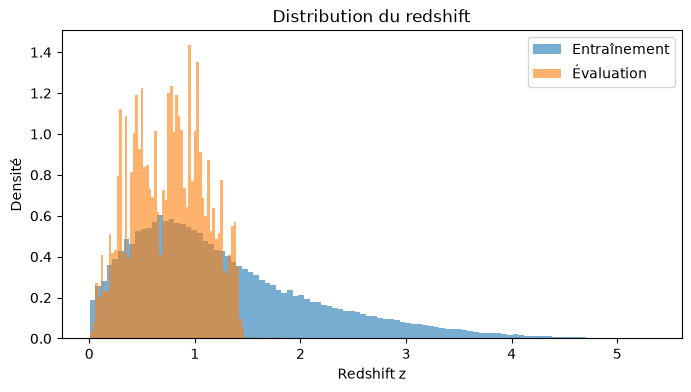

In [7]:
print(pd.concat([pd.Series(y_train, name="train").describe(),
                 pd.Series(y_eval, name="eval").describe()], axis=1))

plt.figure(figsize=(8, 4))
plt.hist(y_train, bins=100, density=True, alpha=0.6, label="Entraînement")
plt.hist(y_eval, bins=100, density=True, alpha=0.6, label="Évaluation")
plt.xlabel("Redshift z")
plt.ylabel("Densité")
plt.title("Distribution du redshift")
plt.legend()
plt.show()

On remarque que les deux jeux de données n'ont **pas la même distribution de redshift z**.

Le jeu d’entraînement a une distribution asymétrique : la majorité des galaxies se situe à bas redshift, avec un maximum vers z ≈ .75, puis une longue traîne vers les grands redshifts, jusqu’à z ≈ 5.34. Les galaxies lointaines sont donc beaucoup moins nombreuses.
75% des galaxies ont un redshift inferieur ou égale à 1.73.

Pour le jeu d’évaluation, c’est différent : les redshifts vont seulement jusqu’à z ≈ 2.52, donc il n’y a pas de galaxies lointaines dedans. On voit aussi beaucoup de pics sur l’histogramme, alors que pour l’entraînement la courbe est assez lisse.

<a id="3-3-latent"></a>
## 3.3 Les espaces latents

Moyennes des dimensions     : de 0.0 à 0.853
Écarts-types des dimensions : de 0.005 à 0.728
nombre de dimensions : 1024


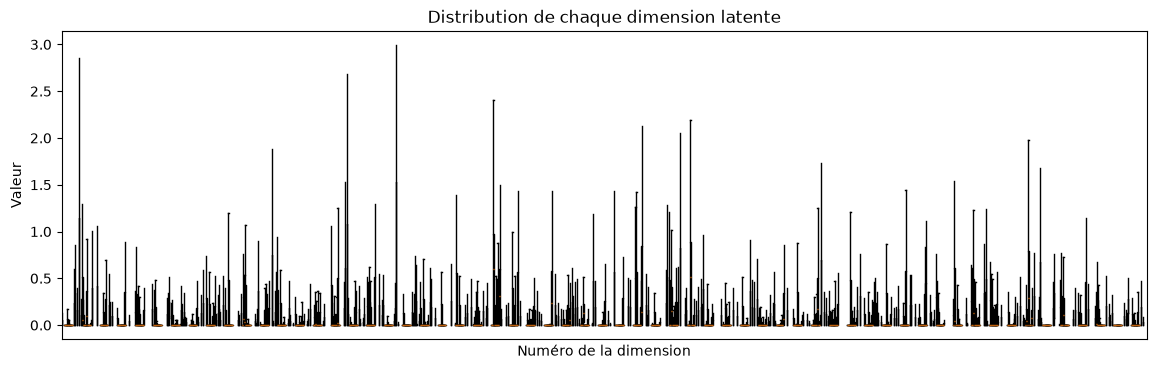

In [8]:
moyennes = x_train.mean(axis=0)
ecarts_types = x_train.std(axis=0)

print("Moyennes des dimensions     : de", moyennes.min().round(3), "à", moyennes.max().round(3))
print("Écarts-types des dimensions : de", ecarts_types.min().round(3), "à", ecarts_types.max().round(3))

print("nombre de dimensions :", x_train.shape[1])

plt.figure(figsize=(14, 4))
plt.boxplot(x_train, showfliers=False)
plt.xlabel("Numéro de la dimension")
plt.ylabel("Valeur")
plt.title("Distribution de chaque dimension latente")
plt.xticks([])
plt.show()

Sur ce graphique, chaque trait correspond au boxplot d'une dimension latente (1024 au total).

On voit que pour presque toutes les dimensions, le boxplot est près de 0, et que la médiane est elle aussi proche de 0. Par contre, certains boxplots montent assez haut. Ça veut dire que pour la plupart des galaxies, les valeurs sont proches de 0, et que seules quelques galaxies ont des valeurs plus grandes. Les distributions sont donc asymétriques.

Les valeurs ne sont jamais négatives et il y a beaucoup de zéros. Cela doit venir de la fonction ReLU utilisée dans le CNN.

<a id="3-4-relation"></a>
## 3.4 Relations avec la cible : quelles dimensions portent l'information ?

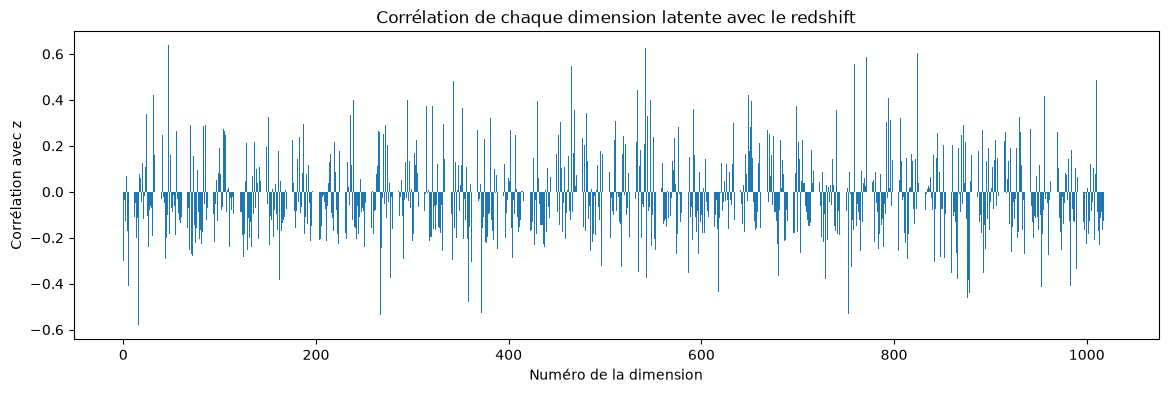

Les 5 dimensions les plus corrélées à z : [ 47 542 824 771  16]


In [ ]:
corr_z = np.array([np.corrcoef(x_train[:, j], y_train)[0, 1] for j in range(x_train.shape[1])])

plt.figure(figsize=(14, 4))
plt.bar(range(len(corr_z)), corr_z)
plt.xlabel("Numéro de la dimension")
plt.ylabel("Corrélation avec z")
plt.title("Corrélation de chaque dimension latente avec le redshift")
plt.show()

print("Les 5 dimensions les plus corrélées à z :")
for j in np.argsort(-np.abs(corr_z))[:5]:
    print("   dimension", j, ": corrélation =", round(corr_z[j], 3))

On remarque tout d’abord que les corrélations entre les variables explicatives et le redshift varient entre -0,6 et 0,6. De plus, la grande majorité de ces variables ont une corrélation entre -0,25 et 0,2. Donc, aucune dimension n’est vraiment très liée au redshift à elle seule. L’information sur le redshift serait alors répartie sur plusieurs dimensions comme attendu.

<a id="3-5-ACP"></a>
## 3.5 ACP

On va faire une **ACP sur les rangs** car nos données ont quelques valeurs très grandes.

Cette ACP est faite sur le **jeu d'entraînement**.

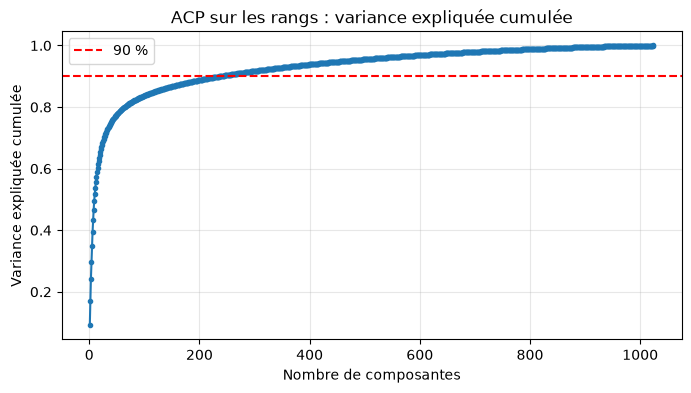

Composantes pour 90 % de la variance : 238


In [10]:
x_rangs = rankdata(x_train, axis=0) / len(x_train)

acp_rangs = PCA().fit(StandardScaler().fit_transform(x_rangs))
variance_cumulee = np.cumsum(acp_rangs.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(variance_cumulee) + 1), variance_cumulee, "o-", markersize=3)
plt.axhline(0.9, color="red", linestyle="--", label="90 %")
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance expliquée cumulée")
plt.title("ACP sur les rangs : variance expliquée cumulée")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Composantes pour 90 % de la variance :", np.argmax(variance_cumulee >= 0.9) + 1)

La courbe monte rapidement au début, puis elle s’aplatit. Il faut **238 composantes** pour garder 90 % de la variance des données. L’information est donc répartie sur beaucoup de dimensions.

Même si on a divisé le nombre de dimensions par environ 4 (de 1024 à 238), ça reste beaucoup trop pour pouvoir les représenter visuellement.

---
<a id="4-visu"></a>
# 4 Visualisation de l'espace latent


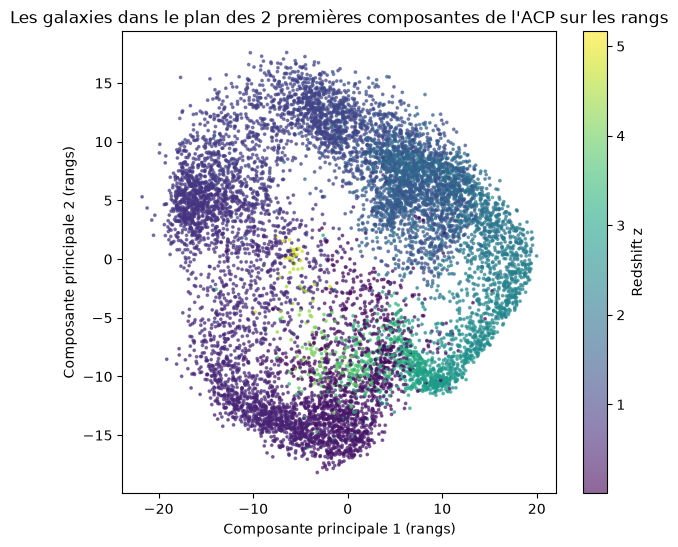

In [11]:
echantillon = np.random.choice(len(y_train), size=min(10000, len(y_train)), replace=False)
X_acp2 = acp_rangs.transform(StandardScaler().fit_transform(x_rangs))[:, :2]

plt.figure(figsize=(7, 6))
nuage = plt.scatter(X_acp2[echantillon, 0], X_acp2[echantillon, 1],
                    c=y_train[echantillon], cmap="viridis", s=3, alpha=0.6)
plt.colorbar(nuage, label="Redshift z")
plt.xlabel("Composante principale 1 (rangs)")
plt.ylabel("Composante principale 2 (rangs)")
plt.title("Les galaxies dans le plan des 2 premières composantes de l'ACP sur les rangs")
plt.show()

Sur ce graphique, on voit que les couleurs sont plutôt mélangées. On remarque tout de même que les galaxies proches sont plutôt d’un côté et les lointaines de l’autre, respéctivement les côtés gauche et droit. Le nuage a une forme ronde et creuse. Donc les 2 premières composantes de l’ACP semblent assez liées au redshift, mais cela reste flou.

---

<a id="5"></a>
# 5. Prétraitement et préparation pour la modélisation

<a id="5-1-blanchiment"></a>
## 5.1 Blanchiment


In [12]:
moyenne_train = x_train.mean(axis=0)
x_train_c = x_train - moyenne_train
x_eval_c = x_eval - moyenne_train

valeurs, vecteurs = np.linalg.eigh(np.cov(x_train_c, rowvar=False))
valeurs = np.maximum(valeurs, 1e-8 * valeurs.max())
sigma_inv_half = vecteurs @ np.diag(1 / np.sqrt(valeurs)) @ vecteurs.T

z_train = x_train_c @ sigma_inv_half

<a id="5-2-varSIR"></a>
## 5.2 Création de nouvelles variables : la SIR


La SIR (régression inverse par tranches) cherche les combinaisons des dimensions latentes
**les plus liées au redshift** :
1. On découpe z en H tranches de même effectif
2. On calcule la moyenne des données blanchies dans chaque tranche
3. Les directions où ces moyennes changent le plus d'une tranche à l'autre sont les plus liées à z

In [13]:
# Découpe y en H tranches avec les quantiles
def faire_tranches(y, H):
    tranches = []
    for i in range(H):
        bas = np.quantile(y, i / H)
        haut = np.quantile(y, (i + 1) / H)
        if i == H - 1:
            masque = (y >= bas) & (y <= haut)
        else:
            masque = (y >= bas) & (y < haut)
        tranches.append(np.where(masque)[0])
    return tranches

# Matrice de la SIR 
def calcul_M(z, tranches):
    n = len(z)
    M = np.zeros((z.shape[1], z.shape[1]))
    for t in tranches:
        if len(t) > 0:
            m_h = z[t].mean(axis=0)
            colonne = m_h.reshape(-1, 1)
            M = M + len(t) / n * (colonne @ colonne.T)
    return M

# Métrique
def sigma_mad(z_pred, z_vrai):
    dz = (z_pred - z_vrai) / (1 + z_vrai)
    return 1.4826 * np.median(np.abs(dz - np.median(dz)))

<a id="5-3"></a>
## 5.3 Création des tranches et directions de la SIR


Nous découpons z en H = 40 tranches contenant chacune **le même nombre de galaxies (environ 3 861)**. Comme la distribution du redshift est très asymétrique, avec peu de galaxies lointaines, un petit nombre de tranches regrouperait tous les grands redshifts dans une seule tranche très large.

In [14]:
H = 40
print(y_train.shape)
tranches = faire_tranches(y_train, H)

seuils = [np.quantile(y_train, i / H) for i in range(1, H)]
print("Seuils :", np.round(seuils, 3), "\n")

for i, t in enumerate(tranches):
    z_min = y_train[t].min()
    z_max = y_train[t].max()
    p_h = len(t) / len(y_train)
    print(f"Tranche {i + 1} : {len(t)} galaxies ({p_h:.1%}), "
          f"z entre {z_min:.3f} et {z_max:.3f}, largeur = {z_max - z_min:.3f}")

(154464,)
Seuils : [0.118 0.197 0.265 0.322 0.373 0.428 0.475 0.525 0.569 0.613 0.659 0.699
 0.742 0.786 0.83  0.873 0.918 0.964 1.01  1.06  1.11  1.163 1.22  1.278
 1.34  1.407 1.479 1.555 1.639 1.729 1.832 1.941 2.062 2.202 2.362 2.543
 2.766 3.05  3.474] 

Tranche 1 : 3857 galaxies (2.5%), z entre 0.005 et 0.118, largeur = 0.113
Tranche 2 : 3864 galaxies (2.5%), z entre 0.118 et 0.197, largeur = 0.079
Tranche 3 : 3864 galaxies (2.5%), z entre 0.197 et 0.265, largeur = 0.068
Tranche 4 : 3862 galaxies (2.5%), z entre 0.265 et 0.322, largeur = 0.058
Tranche 5 : 3860 galaxies (2.5%), z entre 0.322 et 0.373, largeur = 0.051
Tranche 6 : 3863 galaxies (2.5%), z entre 0.373 et 0.428, largeur = 0.055
Tranche 7 : 3862 galaxies (2.5%), z entre 0.428 et 0.475, largeur = 0.047
Tranche 8 : 3861 galaxies (2.5%), z entre 0.475 et 0.525, largeur = 0.050
Tranche 9 : 3852 galaxies (2.5%), z entre 0.525 et 0.569, largeur = 0.044
Tranche 10 : 3869 galaxies (2.5%), z entre 0.569 et 0.613, largeur = 0.044

Avec **40 tranches**, la dernière tranche couvre une plage plus réduite (de z ≈ 3.474 à 5.343), tout en gardant assez de galaxies par tranche pour calculer des moyennes fiables.

<a id="5-4"></a>
## 5.4 Choix du nombre de variables d

d = 1 | sigma_MAD = 0.207
d = 2 | sigma_MAD = 0.0304
d = 3 | sigma_MAD = 0.0252
d = 4 | sigma_MAD = 0.0239
d = 5 | sigma_MAD = 0.023
d = 6 | sigma_MAD = 0.0227
d = 8 | sigma_MAD = 0.0225
d = 10 | sigma_MAD = 0.0222
Toutes les dimensions | sigma_MAD = 0.0253


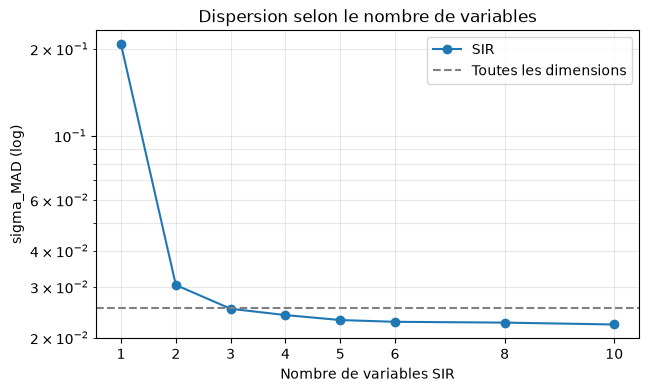

In [15]:
# Directions de la SIR
vp, eta = np.linalg.eigh(calcul_M(z_train, tranches))
vp, eta = vp[::-1], eta[:, ::-1]

liste_d = [1, 2, 3, 4, 5, 6, 8, 10]
dispersion = []

for d_test in liste_d:
    recette_test = sigma_inv_half @ eta[:, :d_test]
    modele = HistGradientBoostingRegressor(random_state=42).fit(x_train_c @ recette_test, y_train)
    z_pred = modele.predict(x_eval_c @ recette_test)
    dispersion.append(sigma_mad(z_pred, y_eval))
    print("d =", d_test, "| sigma_MAD =", round(dispersion[-1], 4))

# Référence : le même modèle avec toutes les dimensions
modele_ref = HistGradientBoostingRegressor(random_state=42).fit(x_train, y_train)
dispersion_ref = sigma_mad(modele_ref.predict(x_eval), y_eval)
print("Toutes les dimensions | sigma_MAD =", round(dispersion_ref, 4))

plt.figure(figsize=(7, 4))
plt.plot(liste_d, dispersion, "o-", label="SIR")
plt.axhline(dispersion_ref, color="gray", linestyle="--", label="Toutes les dimensions")
plt.yscale("log")
plt.xlabel("Nombre de variables SIR")
plt.ylabel("sigma_MAD (log)")
plt.title("Dispersion selon le nombre de variables")
plt.xticks(liste_d)
plt.grid(alpha=0.3, which="both")
plt.legend()
plt.show()

Avec 1 seule variable SIR, le sigma_MAD est assez grand (environ 0,2), donc les prédictions sont pas très précises. Dès qu’on passe à 2 variables, il baisse énormément (environ 0,03). À partir de 3 variables, on arrive au même niveau que quand on utilise les 1024 dimensions (la ligne grise, environ 0,025). Après, ajouter des variables améliore encore un tout petit peu, mais vraiment pas beaucoup, la courbe devient presque plate à partir de 6.

Donc on garde **3 variables**, c’est le plus petit nombre qui donne d’aussi bonnes prédictions qu’avec toutes les dimensions.

<a id="5-5"></a>
## 5.5 Construction des d nouvelles variables

Les nouvelles variables sont construites à partir du jeu d’entraînement, puis on utilise la même transformation pour le jeu d’évaluation. Chaque nouvelle variable est une somme pondérée des dimensions latentes.

In [16]:
d = 3
transformation = sigma_inv_half @ eta[:, :d]

X_sir_train = x_train_c @ transformation
X_sir_eval = x_eval_c @ transformation

print("Nouvelles variables : train =", X_sir_train.shape, "| eval =", X_sir_eval.shape)

Nouvelles variables : train = (154464, 3) | eval = (11639, 3)


<a id="5-6"></a>
## 5.6 Les nouvelles variables et le redshift

Les nouvelles variables n'ont **pas de sens physique** (comme pour l'ACP). On les interprète à travers leur lien avec z.

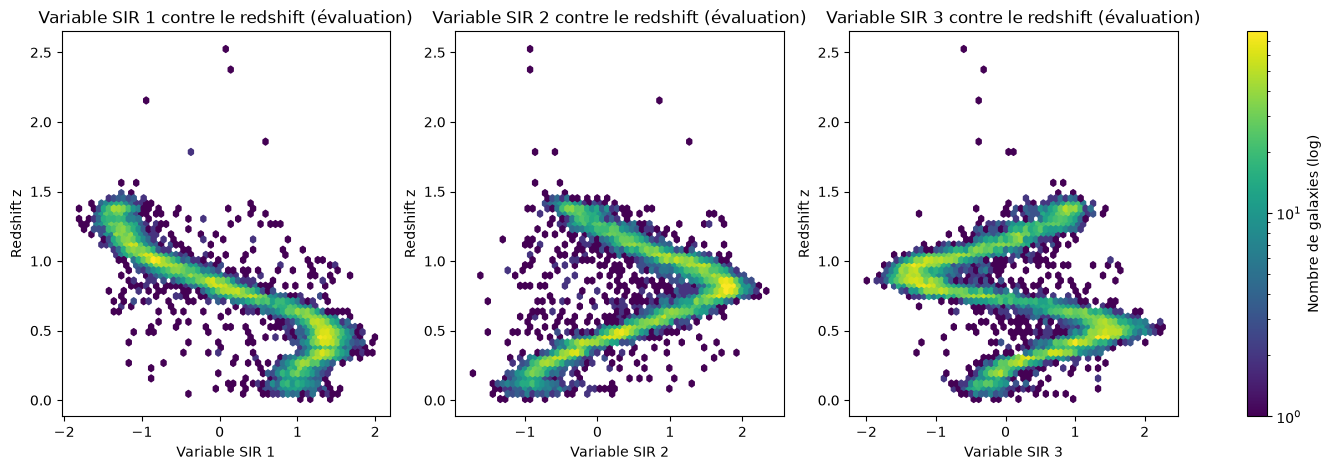

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for k, ax in enumerate(axes):
    hb = ax.hexbin(X_sir_eval[:, k], y_eval, gridsize=60, bins="log", cmap="viridis")
    ax.set_xlabel(f"Variable SIR {k + 1}")
    ax.set_ylabel("Redshift z")
    ax.set_title(f"Variable SIR {k + 1} contre le redshift (évaluation)")
fig.colorbar(hb, ax=axes, label="Nombre de galaxies (log)")
plt.show()

Sur les 3 graphiques, on voit que la plupart des galaxies sont regroupées dans une bande (en jaune). Ça veut dire que **chaque variable SIR est bien liée au redshift**.

On remarque également que ces bandes ne sont pas droites, elles font des virages. Ainsi, pour une même valeur de la variable, il peut y avoir plusieurs redshifts possibles. Avec une seule variable, on ne peut donc pas savoir exactement quel est le redshift. Il faut utiliser les 3 variables ensemble. On voit aussi quelques galaxies isolées, le modèle risque de se tromper sur leur redshift.

Comme les bandes ne sont pas linéaire, cela confirme qu'il faudra utiliser un modèle **non-linéaire** pour les prédictions.

La visualisation 3D :

In [ ]:
ech = np.random.choice(len(y_eval), size=min(5000, len(y_eval)), replace=False)

fig = go.Figure(go.Scatter3d(
    x=X_sir_eval[ech, 0], y=X_sir_eval[ech, 1], z=X_sir_eval[ech, 2], mode="markers",
    marker=dict(size=1.5, opacity=0.6, color=y_eval[ech], colorscale="Viridis",
                cmin=0, cmax=y_train.max(),
                colorbar=dict(title="Redshift (z)", thickness=15, len=0.7)),
    hovertemplate="SIR 1: %{x:.2f}<br>SIR 2: %{y:.2f}<br>SIR 3: %{z:.2f}"
                  "<br>z: %{marker.color:.3f}<extra></extra>"))

fig.update_layout(title="Les 3 variables SIR (couleur = redshift)",
                  scene=dict(xaxis_title="SIR 1", yaxis_title="SIR 2", zaxis_title="SIR 3"),
                  template="plotly_dark", margin=dict(l=0, r=0, b=0, t=40), width=900, height=700)

display(HTML(fig.to_html(full_html=False, include_plotlyjs="cdn")))

<a id="5-7"></a>
## 5.7 Comparaison SIR / ACP

Ici, on affiche l’ACP et la SIR sur le **jeu d’évaluation**, pour voir si ces deux réductions marchent sur des galaxies qu’elles n’ont pas vues (c'est pourquoi les deux graphiques sur l'ACP ne sont pas identiques). Les deux ont été calculées seulement avec le jeu d’entraînement.

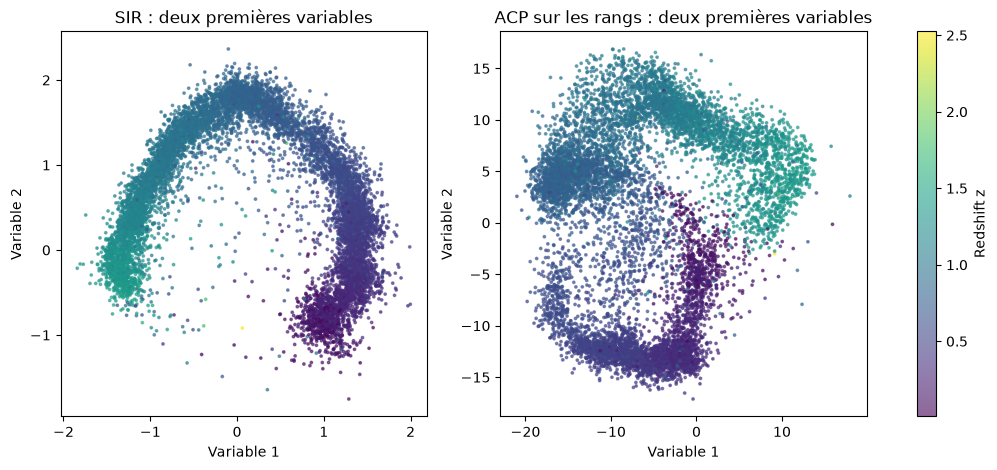

In [18]:
# Calculs des rangs
x_eval_rangs = np.zeros(x_eval.shape)
for j in range(x_train.shape[1]):
    colonne_triee = np.sort(x_train[:, j])
    gauche = np.searchsorted(colonne_triee, x_eval[:, j], side="left")
    droite = np.searchsorted(colonne_triee, x_eval[:, j], side="right")
    x_eval_rangs[:, j] = (gauche + droite + 1) / 2 / len(x_train)

# Même ACP sur les rangs que dans l'exploration
normaliseur_rangs = StandardScaler().fit(x_rangs)
X_acp_eval = acp_rangs.transform(normaliseur_rangs.transform(x_eval_rangs))[:, :2]

ech_eval = np.random.choice(len(y_eval), size=min(10000, len(y_eval)), replace=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (nom, Xp) in zip(axes, [("SIR", X_sir_eval), ("ACP sur les rangs", X_acp_eval)]):
    nuage = ax.scatter(Xp[ech_eval, 0], Xp[ech_eval, 1], c=y_eval[ech_eval], cmap="viridis", s=3, alpha=0.6)
    ax.set_title(f"{nom} : deux premières variables")
    ax.set_xlabel("Variable 1")
    ax.set_ylabel("Variable 2")
fig.colorbar(nuage, ax=axes, label="Redshift z")
plt.show()

Et la visualisation en 3D :

In [ ]:
X_acp_eval3 = acp_rangs.transform(normaliseur_rangs.transform(x_eval_rangs))[:, :3]

ech = np.random.choice(len(y_eval), size=min(5000, len(y_eval)), replace=False)

fig = make_subplots(rows=1, cols=2, specs=[[{"type": "scene"}, {"type": "scene"}]],
                    subplot_titles=["SIR : 3 premières variables", "ACP sur les rangs : 3 premières composantes"])

for col, X3 in [(1, X_sir_eval), (2, X_acp_eval3)]:
    fig.add_trace(go.Scatter3d(
        x=X3[ech, 0], y=X3[ech, 1], z=X3[ech, 2], mode="markers",
        marker=dict(size=1.5, opacity=0.6, color=y_eval[ech], colorscale="Viridis",
                    cmin=0, cmax=y_train.max(), showscale=(col == 2),
                    colorbar=dict(title="Redshift (z)", thickness=15, len=0.7)),
        hovertemplate="Var 1: %{x:.2f}<br>Var 2: %{y:.2f}<br>Var 3: %{z:.2f}<br>z: %{marker.color:.3f}<extra></extra>"),
        row=1, col=col)

fig.update_scenes(xaxis_title="Variable 1", yaxis_title="Variable 2", zaxis_title="Variable 3")
fig.update_layout(template="plotly_dark", margin=dict(l=0, r=0, b=0, t=40),
                  width=1100, height=600, showlegend=False)

display(HTML(fig.to_html(full_html=False, include_plotlyjs="cdn")))

Les couleurs sont mieux rangées avec la SIR, ça montre qu’une méthode qui se sert du redshift garde mieux ce qui est utile pour le prédire qu’une méthode qui garde seulement ce qui varie le plus, comme l’ACP.

Pour **la SIR**, on voit une bande en forme d’arc. Les couleurs changent petit à petit le long de l’arc : en bas à droite c’est violet (petit redshift) et plus on va vers la gauche plus le redshift augmente. Donc les galaxies sont bien rangées selon z, la SIR marche bien. Ça confirme aussi ce qu’on avait vu avant, que le redshift suit une courbe. Il y a quand même quelques galaxies au milieu qui sont un peu toutes seules.

Pour **l’ACP**, il y a aussi une forme mais c’est beaucoup plus étalé. Les couleurs sont plus mélangées, surtout au milieu où on a des redshifts différents au même endroit. L’ACP garde un peu d’info sur le redshift mais moins bien que la SIR.

Donc pour réduire les dimensions avant le modèle, il est préférable de **garde la SIR**. Avec juste 2 variables les galaxies sont déjà bien rangées, alors que l’ACP mélange encore beaucoup de choses qui n’ont rien à voir avec z.

---
<a id="6"></a>
# 6. Conclusion
...